# Tier 2 (v1): Health News Credibility Assessment

The first version of Tier 2: a binary credible / not credible model and a ten criteria model, trained on FakeHealth articles.

## 1. Setup

In [1]:
import os, sys, json, random, re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
os.environ["HF_HUB_DISABLE_XET"] = "1"

SEED = 42
random.seed(SEED); np.random.seed(SEED)

PROJECT_ROOT  = Path.cwd()
FAKEHEALTH    = PROJECT_ROOT / "datasets" / "raw" / "FakeHealth" / "FakeHealth-master" / "dataset"
PROCESSED_DIR = PROJECT_ROOT / "datasets" / "processed_tier2"
OUTPUTS_DIR   = PROJECT_ROOT / "outputs"
FIGURES_DIR   = OUTPUTS_DIR / "figures"
MODELS_DIR    = PROJECT_ROOT / "models"
for d in (PROCESSED_DIR, OUTPUTS_DIR, FIGURES_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

CREDIBILITY_THRESHOLD = 3          # HealthNewsReview convention: rating >= 3 is acceptable
LABELS   = ["NOT_CREDIBLE", "CREDIBLE"]
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
ID2LABEL = {i: l for l, i in LABEL2ID.items()}

# The ten criteria, keyed by a stable short name. HealthRelease phrases them as
# "Does the news release ..." and HealthStory as "Does the story ...", so we match
# on distinctive keywords rather than the full question string.
CRITERIA = {
    "costs":            "cost",
    "benefits":         "quantify the benefits",
    "harms":            "harms",
    "evidence_quality": "quality of the evidence",
    "disease_mongering":"disease-mongering",
    "independent_srcs": "independent sources",
    "alternatives":     "compare",
    "availability":     "availability",
    "novelty":          "novelty",
    "press_release":    "news release",     # note: matched last, see resolve_criterion
}
CRITERION_KEYS = list(CRITERIA)

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
print(f"Project root : {PROJECT_ROOT}")
print(f"Criteria     : {len(CRITERION_KEYS)}")

Project root : C:\Users\nihal\Desktop\Project Phase
Criteria     : 10


## 2. Loading FakeHealth

Each article is joined with its review: the star rating and the ten criteria judgements.

In [2]:
CONTENT_PREFIX = {"HealthRelease": "news_reviews", "HealthStory": "story_reviews"}

def resolve_criterion(question: str):
    """Map a criterion question onto one of the ten canonical keys."""
    q = str(question).lower()
    # 'relies on a news release' must be checked before the generic 'news release'
    # wording used by the HealthRelease subset for every other question.
    if "solely" in q or "largely on a news release" in q or "press release" in q:
        return "press_release"
    for key, kw in CRITERIA.items():
        if key == "press_release":
            continue
        if kw in q:
            return key
    return None


def load_fakehealth():
    rows, dropped = [], 0
    for subset, prefix in CONTENT_PREFIX.items():
        reviews = json.load(open(FAKEHEALTH / "reviews" / f"{subset}.json", encoding="utf-8"))
        for i, rev in enumerate(reviews):
            idx = str(i).zfill(5)
            cpath = FAKEHEALTH / "content" / subset / f"{prefix}_{idx}.json"
            if not cpath.exists() or rev.get("rating") is None:
                dropped += 1; continue
            content = json.load(open(cpath, encoding="utf-8"))
            text = (content.get("text") or "").strip()
            if len(text.split()) < 50:
                dropped += 1; continue

            row = {
                "article_id": f"{subset}_{idx}",
                "subset": subset,
                "title": content.get("title", ""),
                "text": text,
                "rating": int(rev["rating"]),
                "review_summary": (rev.get("summary") or {}).get("Our Review Summary", "")
                                  if isinstance(rev.get("summary"), dict) else "",
            }
            # ten criteria: 1 = FAILS the criterion, 0 = satisfies, NaN = not applicable
            for c in (rev.get("criteria") or []):
                if not isinstance(c, dict):
                    continue
                key = resolve_criterion(c.get("question", ""))
                if key is None:
                    continue
                a = str(c.get("answer", "")).strip().lower()
                row[f"fail_{key}"] = (1.0 if a == "not satisfactory"
                                      else 0.0 if a == "satisfactory" else np.nan)
                row[f"why_{key}"] = str(c.get("explanation", ""))
            rows.append(row)
    print(f"dropped {dropped} reviews (missing content, missing rating, or text < 50 words)")
    return pd.DataFrame(rows)


art = load_fakehealth()
art = art.drop_duplicates(subset=["text"]).reset_index(drop=True)
art["binary_label"] = np.where(art["rating"] >= CREDIBILITY_THRESHOLD, "CREDIBLE", "NOT_CREDIBLE")
art["n_words"] = art["text"].str.split().str.len()

print(f"\nusable articles: {len(art):,}")
print(art["binary_label"].value_counts().to_string())
print(f"\nmajority-class baseline: {art['binary_label'].value_counts(normalize=True).max():.3f}")

dropped 177 reviews (missing content, missing rating, or text < 50 words)

usable articles: 2,119
binary_label
CREDIBLE        1409
NOT_CREDIBLE     710

majority-class baseline: 0.665


In [3]:
missing = {k: art[f"fail_{k}"].isna().mean() for k in CRITERION_KEYS}
cover = pd.DataFrame({
    "fail_rate": {k: art[f"fail_{k}"].mean() for k in CRITERION_KEYS},
    "not_applicable": missing,
}).sort_values("fail_rate", ascending=False)
cover.index.name = "criterion"
print("How often each journalistic standard is FAILED:\n")
print(cover.round(3).to_string())

How often each journalistic standard is FAILED:

                   fail_rate  not_applicable
criterion                                   
costs                  0.753           0.164
harms                  0.665           0.075
benefits               0.665           0.009
evidence_quality       0.627           0.001
alternatives           0.514           0.050
independent_srcs       0.482           0.282
novelty                0.307           0.034
availability           0.273           0.135
disease_mongering      0.129           0.038
press_release          0.108           0.336


## 3. Exploratory analysis

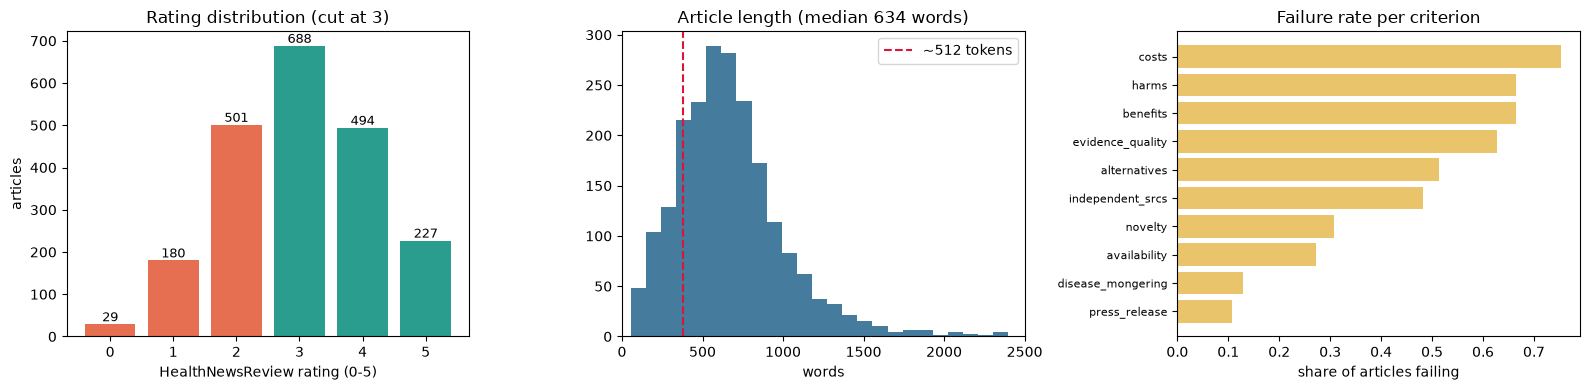

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

rt = art["rating"].value_counts().sort_index()
bars = axes[0].bar(rt.index, rt.values,
                   color=["#e76f51" if r < CREDIBILITY_THRESHOLD else "#2a9d8f" for r in rt.index])
axes[0].set_title(f"Rating distribution (cut at {CREDIBILITY_THRESHOLD})")
axes[0].set_xlabel("HealthNewsReview rating (0-5)"); axes[0].set_ylabel("articles")
for b, v in zip(bars, rt.values):
    axes[0].text(b.get_x()+b.get_width()/2, v, str(v), ha="center", va="bottom", fontsize=9)

axes[1].hist(art["n_words"], bins=45, color="#457b9d")
axes[1].axvline(380, color="crimson", ls="--", label="~512 tokens")
axes[1].set_title(f"Article length (median {art['n_words'].median():.0f} words)")
axes[1].set_xlabel("words"); axes[1].set_xlim(0, 2500); axes[1].legend()

cr = cover["fail_rate"].sort_values()
axes[2].barh(range(len(cr)), cr.values, color="#e9c46a")
axes[2].set_yticks(range(len(cr))); axes[2].set_yticklabels(cr.index, fontsize=8)
axes[2].set_title("Failure rate per criterion"); axes[2].set_xlabel("share of articles failing")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "tier2_data_overview.png", dpi=150)
plt.show()

### 3.1 Are the criteria just measuring one thing?

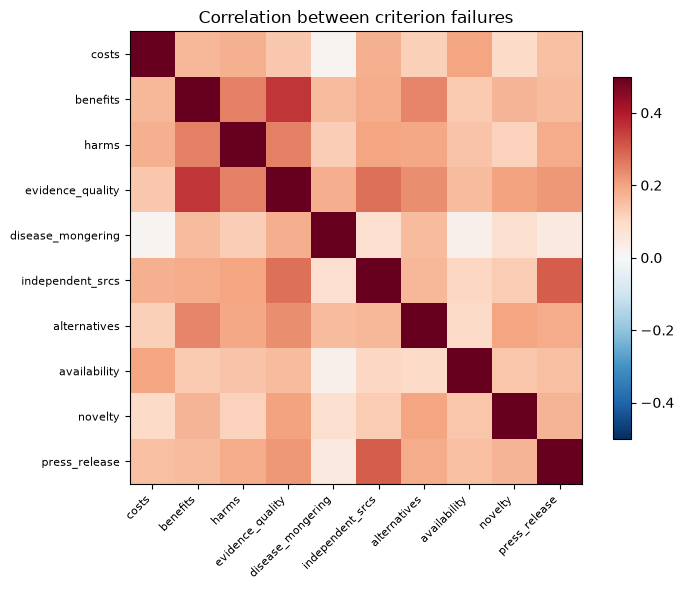

mean |correlation| between different criteria: 0.164
max  |correlation|                           : 0.357

Low correlations mean the criteria capture largely INDEPENDENT failure modes,
so predicting them individually genuinely adds information over the overall rating.


In [5]:
crit_cols = [f"fail_{k}" for k in CRITERION_KEYS]
corr = art[crit_cols].corr()
corr.index = [c.replace("fail_", "") for c in corr.index]
corr.columns = corr.index

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index, fontsize=8)
ax.set_title("Correlation between criterion failures")
fig.colorbar(im, shrink=0.8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tier2_criteria_correlation.png", dpi=150)
plt.show()

off = corr.where(~np.eye(len(corr), dtype=bool))
print(f"mean |correlation| between different criteria: {off.abs().stack().mean():.3f}")
print(f"max  |correlation|                           : {off.abs().stack().max():.3f}")
print()
print("Low correlations mean the criteria capture largely INDEPENDENT failure modes,")
print("so predicting them individually genuinely adds information over the overall rating.")

## 4. Train / validation / test split

In [6]:
from sklearn.model_selection import train_test_split

train_val, test_df = train_test_split(art, test_size=0.15, random_state=SEED,
                                      stratify=art["binary_label"])
train_df, val_df = train_test_split(train_val, test_size=0.1765, random_state=SEED,
                                    stratify=train_val["binary_label"])
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

assert not (set(train_df.article_id) & set(test_df.article_id)), "split leakage!"

summary = pd.DataFrame({
    n: d["binary_label"].value_counts()
    for n, d in [("train", train_df), ("validation", val_df), ("test", test_df)]
}).fillna(0).astype(int)
summary.loc["TOTAL"] = summary.sum()
print(summary.to_string())
print()
for n, d in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"{n:<11} {len(d):>5} articles   median {d['n_words'].median():.0f} words")

keep = ["article_id", "subset", "title", "text", "rating", "binary_label",
        "review_summary"] + crit_cols + [f"why_{k}" for k in CRITERION_KEYS]
for n, d in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    d[keep].to_csv(PROCESSED_DIR / f"{n}.csv", index=False)
print(f"\nsaved to {PROCESSED_DIR}")

              train  validation  test
binary_label                         
CREDIBLE        986         212   211
NOT_CREDIBLE    497         106   107
TOTAL          1483         318   318

train        1483 articles   median 640 words
validation    318 articles   median 628 words
test          318 articles   median 620 words

saved to C:\Users\nihal\Desktop\Project Phase\datasets\processed_tier2


## 5. Model setup

In [7]:
import torch
import torch.nn as nn
from datasets import Dataset
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support,
                             roc_auc_score)
from sklearn.utils.class_weight import compute_class_weight
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding,
                          EarlyStoppingCallback)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)

PUBMEDBERT = "microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract-fulltext"
BERTBASE   = "bert-base-uncased"
MAX_LEN    = 512
BATCH      = 8

print(f"Device: {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU   : {torch.cuda.get_device_name(0)} "
          f"({torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB)")

Device: cuda
GPU   : NVIDIA GeForce RTX 5050 Laptop GPU (8.5 GB)


## 6. Binary credibility model

In [8]:
def article_text(frame):
    """Title + body. The headline carries a lot of the hype signal."""
    return (frame["title"].fillna("").astype(str) + ". " +
            frame["text"].fillna("").astype(str)).tolist()


def binary_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    p, r, f1, _ = precision_recall_fscore_support(
        labels, preds, average="binary", pos_label=LABEL2ID["NOT_CREDIBLE"], zero_division=0)
    return {"accuracy": accuracy_score(labels, preds),
            "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
            "precision_notcred": p, "recall_notcred": r, "f1_notcred": f1}


def make_weighted_trainer(class_weights):
    w = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
    class WeightedTrainer(Trainer):
        def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
            labels = inputs.pop("labels")
            out = model(**inputs)
            loss = nn.CrossEntropyLoss(weight=w)(out.logits.view(-1, 2), labels.view(-1))
            return (loss, out) if return_outputs else loss
    return WeightedTrainer


def train_binary(base_model, run_name, epochs=4, lr=2e-5, force_retrain=False):
    save_dir = MODELS_DIR / run_name
    save_dir.mkdir(parents=True, exist_ok=True)
    has_ckpt = (save_dir / "config.json").exists() and not force_retrain
    tok = AutoTokenizer.from_pretrained(save_dir if has_ckpt else base_model)

    def encode(frame):
        ds = Dataset.from_dict({"text": article_text(frame),
                                "labels": frame["binary_label"].map(LABEL2ID).astype(int).tolist()})
        return ds.map(lambda b: tok(b["text"], truncation=True, max_length=MAX_LEN),
                      batched=True, remove_columns=["text"])

    seconds = None
    if has_ckpt:
        print(f"[{run_name}] loading cached checkpoint")
        model = AutoModelForSequenceClassification.from_pretrained(save_dir).to(DEVICE)
    else:
        print(f"[{run_name}] training {base_model}")
        model = AutoModelForSequenceClassification.from_pretrained(
            base_model, num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID).to(DEVICE)
        cw = compute_class_weight("balanced", classes=np.array([0, 1]),
                                  y=train_df["binary_label"].map(LABEL2ID).values)
        args = TrainingArguments(
            output_dir=str(OUTPUTS_DIR / "trainer_ckpts" / run_name),
            eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
            learning_rate=lr, per_device_train_batch_size=BATCH,
            per_device_eval_batch_size=BATCH * 2, num_train_epochs=epochs,
            warmup_ratio=0.1, weight_decay=0.01, load_best_model_at_end=True,
            metric_for_best_model="f1_macro", greater_is_better=True,
            logging_steps=100, report_to=[], seed=SEED,
            fp16=(DEVICE == "cuda"), disable_tqdm=True)
        trainer = make_weighted_trainer(cw)(
            model=model, args=args, train_dataset=encode(train_df), eval_dataset=encode(val_df),
            processing_class=tok, data_collator=DataCollatorWithPadding(tok),
            compute_metrics=binary_metrics,
            callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])
        t0 = time.time(); trainer.train(); seconds = time.time() - t0
        model.save_pretrained(save_dir); tok.save_pretrained(save_dir)
        print(f"[{run_name}] trained in {seconds/60:.1f} min")

    probs = predict_binary(model, tok, test_df)
    y = test_df["binary_label"].map(LABEL2ID).astype(int).to_numpy()
    yp = probs.argmax(-1)
    res = {"run": run_name, "backbone": base_model,
           "train_minutes": None if seconds is None else round(seconds/60, 2),
           "accuracy": round(accuracy_score(y, yp), 4),
           "f1_macro": round(f1_score(y, yp, average="macro", zero_division=0), 4),
           "recall_notcred": round(float(precision_recall_fscore_support(
               y, yp, average="binary", pos_label=LABEL2ID["NOT_CREDIBLE"], zero_division=0)[1]), 4),
           "roc_auc": round(roc_auc_score(y, probs[:, LABEL2ID["CREDIBLE"]]), 4)}
    print(f"[{run_name}] TEST acc={res['accuracy']} macroF1={res['f1_macro']} "
          f"recall(NOT_CREDIBLE)={res['recall_notcred']}")
    return res, model, tok, probs, y


@torch.no_grad()
def predict_binary(model, tok, frame, bs=16):
    model.eval(); texts = article_text(frame); out = []
    for i in range(0, len(texts), bs):
        enc = tok(texts[i:i+bs], truncation=True, padding=True,
                  max_length=MAX_LEN, return_tensors="pt")
        enc = {k: v.to(DEVICE) for k, v in enc.items()}
        out.append(torch.softmax(model(**enc).logits, -1).float().cpu().numpy())
    return np.concatenate(out)

print("binary helpers defined")

binary helpers defined


In [9]:
bin_results = []
res_pm, model_bin, tok_bin, probs_bin, y_test = train_binary(PUBMEDBERT, "tier2_pubmedbert_binary")
bin_results.append(res_pm)

[tier2_pubmedbert_binary] loading cached checkpoint


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 15368.79it/s]

[tier2_pubmedbert_binary] TEST acc=0.6887 macroF1=0.6609 recall(NOT_CREDIBLE)=0.5981


In [10]:
res_bb, *_ = train_binary(BERTBASE, "tier2_bertbase_binary")
bin_results.append(res_bb)

majority = test_df["binary_label"].value_counts(normalize=True).max()
bin_df = pd.DataFrame(bin_results)
bin_df["backbone"] = bin_df["backbone"].str.replace(
    "microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract-fulltext", "PubMedBERT", regex=False)
bin_df.to_csv(OUTPUTS_DIR / "tier2_binary_comparison.csv", index=False)
print(f"\nmajority-class baseline: {majority:.3f}\n")
print(bin_df.to_string(index=False))

[tier2_bertbase_binary] loading cached checkpoint


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 15529.02it/s]

[tier2_bertbase_binary] TEST acc=0.6981 macroF1=0.5958 recall(NOT_CREDIBLE)=0.2897

majority-class baseline: 0.664

                    run          backbone train_minutes  accuracy  f1_macro  recall_notcred  roc_auc
tier2_pubmedbert_binary        PubMedBERT          None    0.6887    0.6609          0.5981   0.7275
  tier2_bertbase_binary bert-base-uncased          None    0.6981    0.5958          0.2897   0.6713


              precision    recall  f1-score   support

NOT_CREDIBLE      0.533     0.598     0.564       107
    CREDIBLE      0.783     0.735     0.758       211

    accuracy                          0.689       318
   macro avg      0.658     0.666     0.661       318
weighted avg      0.699     0.689     0.693       318



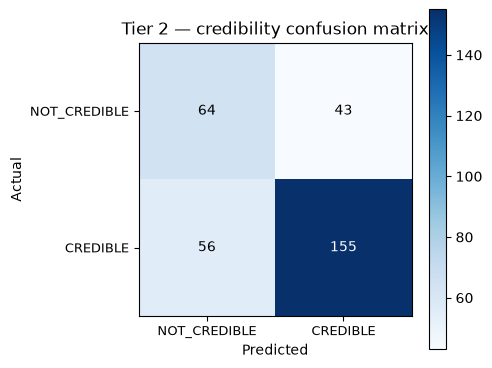

In [11]:
print(classification_report(y_test, probs_bin.argmax(-1), target_names=LABELS,
                            digits=3, zero_division=0))

cm = confusion_matrix(y_test, probs_bin.argmax(-1))
fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(LABELS, fontsize=9)
ax.set_yticks([0, 1]); ax.set_yticklabels(LABELS, fontsize=9)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Tier 2 — credibility confusion matrix")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max()/2 else "black")
fig.colorbar(im); plt.tight_layout()
plt.savefig(FIGURES_DIR / "tier2_confusion_matrix.png", dpi=150)
plt.show()

## 7. Criteria model: predicting why

Ten sigmoid outputs, one per criterion. Criteria marked Not Applicable are masked out of the loss.

In [12]:
CRIT_COLS = [f"fail_{k}" for k in CRITERION_KEYS]

def criteria_targets(frame):
    """-1 marks Not Applicable and is masked out of the loss."""
    return frame[CRIT_COLS].fillna(-1.0).values.astype(np.float32)


# how often each criterion is failed, among applicable cases -> pos_weight
_t = criteria_targets(train_df)
_valid = _t >= 0
pos_rate = np.array([_t[:, j][_valid[:, j]].mean() for j in range(len(CRITERION_KEYS))])
pos_weight = torch.tensor(((1 - pos_rate) / np.clip(pos_rate, 1e-3, None)).astype(np.float32)).to(DEVICE)
print("criterion            fail-rate  pos_weight")
for k, r, w in zip(CRITERION_KEYS, pos_rate, pos_weight.cpu().numpy()):
    print(f"  {k:<20} {r:.3f}      {w:.2f}")


class MaskedBCETrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")                      # (B, 10) with -1 = N/A
        out = model(**inputs)
        logits = out.logits
        mask = (labels >= 0).float()
        target = labels.clamp(min=0)
        loss_el = nn.BCEWithLogitsLoss(reduction="none", pos_weight=pos_weight)(logits, target)
        loss = (loss_el * mask).sum() / mask.sum().clamp(min=1)
        return (loss, out) if return_outputs else loss


def criteria_metrics(eval_pred):
    logits, labels = eval_pred
    preds = (1 / (1 + np.exp(-logits)) >= 0.5).astype(int)
    mask = labels >= 0
    f1s = [f1_score(labels[:, j][mask[:, j]], preds[:, j][mask[:, j]], zero_division=0)
           for j in range(labels.shape[1]) if mask[:, j].sum() > 0]
    acc = (preds[mask] == labels[mask]).mean()
    return {"criteria_f1_macro": float(np.mean(f1s)), "criteria_accuracy": float(acc)}

criterion            fail-rate  pos_weight
  costs                0.752      0.33
  benefits             0.666      0.50
  harms                0.666      0.50
  evidence_quality     0.635      0.57
  disease_mongering    0.135      6.43
  independent_srcs     0.487      1.05
  alternatives         0.507      0.97
  availability         0.278      2.59
  novelty              0.304      2.29
  press_release        0.105      8.55


In [13]:
def train_criteria(base_model, run_name, epochs=5, lr=2e-5, force_retrain=False):
    save_dir = MODELS_DIR / run_name
    save_dir.mkdir(parents=True, exist_ok=True)
    has_ckpt = (save_dir / "config.json").exists() and not force_retrain
    tok = AutoTokenizer.from_pretrained(save_dir if has_ckpt else base_model)

    def encode(frame):
        ds = Dataset.from_dict({"text": article_text(frame),
                                "labels": criteria_targets(frame).tolist()})
        return ds.map(lambda b: tok(b["text"], truncation=True, max_length=MAX_LEN),
                      batched=True, remove_columns=["text"])

    seconds = None
    if has_ckpt:
        print(f"[{run_name}] loading cached checkpoint")
        model = AutoModelForSequenceClassification.from_pretrained(save_dir).to(DEVICE)
    else:
        print(f"[{run_name}] training multi-label head ({len(CRITERION_KEYS)} criteria)")
        model = AutoModelForSequenceClassification.from_pretrained(
            base_model, num_labels=len(CRITERION_KEYS),
            problem_type="multi_label_classification").to(DEVICE)
        args = TrainingArguments(
            output_dir=str(OUTPUTS_DIR / "trainer_ckpts" / run_name),
            eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
            learning_rate=lr, per_device_train_batch_size=BATCH,
            per_device_eval_batch_size=BATCH * 2, num_train_epochs=epochs,
            warmup_ratio=0.1, weight_decay=0.01, load_best_model_at_end=True,
            metric_for_best_model="criteria_f1_macro", greater_is_better=True,
            logging_steps=100, report_to=[], seed=SEED,
            fp16=(DEVICE == "cuda"), disable_tqdm=True)
        trainer = MaskedBCETrainer(
            model=model, args=args, train_dataset=encode(train_df), eval_dataset=encode(val_df),
            processing_class=tok, data_collator=DataCollatorWithPadding(tok),
            compute_metrics=criteria_metrics,
            callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])
        t0 = time.time(); trainer.train(); seconds = time.time() - t0
        model.save_pretrained(save_dir); tok.save_pretrained(save_dir)
        print(f"[{run_name}] trained in {seconds/60:.1f} min")
    return model, tok, seconds


@torch.no_grad()
def predict_criteria(model, tok, frame, bs=16):
    model.eval(); texts = article_text(frame); out = []
    for i in range(0, len(texts), bs):
        enc = tok(texts[i:i+bs], truncation=True, padding=True,
                  max_length=MAX_LEN, return_tensors="pt")
        enc = {k: v.to(DEVICE) for k, v in enc.items()}
        out.append(torch.sigmoid(model(**enc).logits).float().cpu().numpy())
    return np.concatenate(out)


model_crit, tok_crit, _ = train_criteria(PUBMEDBERT, "tier2_pubmedbert_criteria")
crit_probs = predict_criteria(model_crit, tok_crit, test_df)
print(f"\npredicted criteria matrix: {crit_probs.shape}")

[tier2_pubmedbert_criteria] loading cached checkpoint


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 15910.00it/s]


predicted criteria matrix: (318, 10)


### 7.1 A decision threshold per criterion

In [14]:
from sklearn.metrics import matthews_corrcoef, balanced_accuracy_score

val_crit_probs = predict_criteria(model_crit, tok_crit, val_df)
y_val_crit = criteria_targets(val_df)

CRIT_THRESHOLDS = {}
tune_rows = []
for j, k in enumerate(CRITERION_KEYS):
    m = y_val_crit[:, j] >= 0
    if m.sum() < 10:
        CRIT_THRESHOLDS[k] = 0.5
        continue
    yt = y_val_crit[:, j][m].astype(int)
    probs_j = val_crit_probs[:, j][m]

    # rate-matching: pick the cut-off where the predicted failure rate equals the
    # observed base rate. A constant classifier is impossible by construction.
    thr = float(np.quantile(probs_j, 1.0 - yt.mean()))
    CRIT_THRESHOLDS[k] = round(thr, 3)

    pred_t = (probs_j >= thr).astype(int)
    tune_rows.append({
        "criterion": k, "threshold": round(thr, 3),
        "val_mcc": round(matthews_corrcoef(yt, pred_t) if len(set(pred_t)) > 1 else 0.0, 3),
        "val_bal_acc": round(balanced_accuracy_score(yt, pred_t), 3),
        "val_f1": round(f1_score(yt, pred_t, zero_division=0), 3),
        # these two columns should track each other; divergence signals degeneracy
        "predicts_fail": round(float(pred_t.mean()), 3),
        "actual_fail": round(float(yt.mean()), 3),
    })

tune_df = pd.DataFrame(tune_rows)
tune_df.to_csv(OUTPUTS_DIR / "tier2_criteria_thresholds.csv", index=False)
print(tune_df.to_string(index=False))

_deg = tune_df[(tune_df["predicts_fail"] > 0.95) | (tune_df["predicts_fail"] < 0.05)]
_gap = (tune_df["predicts_fail"] - tune_df["actual_fail"]).abs().mean()
print(f"\nmean validation MCC          : {tune_df['val_mcc'].mean():.3f}")
print(f"mean validation balanced acc : {tune_df['val_bal_acc'].mean():.3f}")
print(f"degenerate criteria          : {len(_deg)}/{len(tune_df)}   (was 4/10 under F1 tuning)")
print(f"mean |predicts_fail - actual| : {_gap:.3f}   (was 0.330 under F1 tuning)")

        criterion  threshold  val_mcc  val_bal_acc  val_f1  predicts_fail  actual_fail
            costs      0.450    0.203        0.601   0.784          0.729        0.729
         benefits      0.479    0.195        0.597   0.733          0.669        0.669
            harms      0.514    0.065        0.532   0.668          0.645        0.645
 evidence_quality      0.527    0.149        0.574   0.673          0.616        0.616
disease_mongering      0.564   -0.000        0.500   0.128          0.128        0.128
 independent_srcs      0.525    0.147        0.573   0.534          0.454        0.454
     alternatives      0.515    0.084        0.542   0.580          0.542        0.542
     availability      0.678    0.171        0.586   0.392          0.266        0.266
          novelty      0.622    0.113        0.556   0.400          0.324        0.324
    press_release      0.780    0.169        0.584   0.261          0.111        0.111

mean validation MCC          : 0.130
mean 

In [15]:
y_crit = criteria_targets(test_df)
mask   = y_crit >= 0
thr_vec = np.array([CRIT_THRESHOLDS[k] for k in CRITERION_KEYS])
pred_c = (crit_probs >= thr_vec).astype(int)          # tuned thresholds, from validation

rows = []
for j, k in enumerate(CRITERION_KEYS):
    m = mask[:, j]
    if m.sum() == 0:
        continue
    yt, yp = y_crit[:, j][m].astype(int), pred_c[:, j][m]
    p, r, f1, _ = precision_recall_fscore_support(yt, yp, average="binary", zero_division=0)
    rows.append({"criterion": k, "n": int(m.sum()), "fail_rate": round(yt.mean(), 3),
                 "precision": round(p, 3), "recall": round(r, 3), "f1": round(f1, 3),
                 "accuracy": round((yt == yp).mean(), 3)})

crit_df = pd.DataFrame(rows).sort_values("f1", ascending=False)
crit_df.to_csv(OUTPUTS_DIR / "tier2_criteria_performance.csv", index=False)
print(f"macro F1 across criteria : {crit_df['f1'].mean():.3f}")
print(f"mean accuracy            : {crit_df['accuracy'].mean():.3f}\n")
print(crit_df.to_string(index=False))

macro F1 across criteria : 0.523
mean accuracy            : 0.675

        criterion   n  fail_rate  precision  recall    f1  accuracy
            costs 262      0.779      0.858   0.770 0.811     0.721
            harms 294      0.677      0.789   0.678 0.730     0.660
 evidence_quality 318      0.601      0.733   0.675 0.703     0.657
         benefits 313      0.655      0.723   0.673 0.697     0.617
     alternatives 305      0.515      0.597   0.586 0.592     0.584
 independent_srcs 233      0.489      0.595   0.412 0.487     0.575
          novelty 306      0.304      0.389   0.398 0.394     0.627
    press_release 216      0.120      0.450   0.346 0.391     0.870
     availability 272      0.254      0.319   0.319 0.319     0.654
disease_mongering 308      0.104      0.095   0.125 0.108     0.786


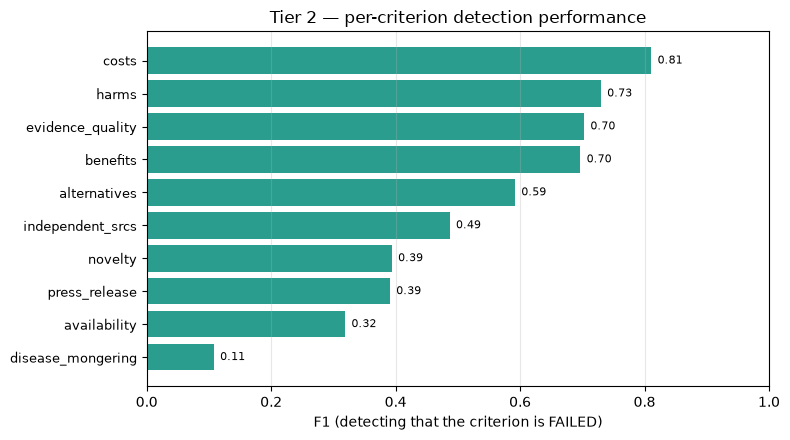

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
d = crit_df.sort_values("f1")
ax.barh(range(len(d)), d["f1"], color="#2a9d8f")
ax.set_yticks(range(len(d))); ax.set_yticklabels(d["criterion"], fontsize=9)
ax.set_xlabel("F1 (detecting that the criterion is FAILED)")
ax.set_title("Tier 2 — per-criterion detection performance")
ax.set_xlim(0, 1); ax.grid(axis="x", alpha=0.3)
for i, (v, n) in enumerate(zip(d["f1"], d["fail_rate"])):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tier2_criteria_performance.png", dpi=150)
plt.show()

### 7.2 Can the criteria predict overall credibility?

In [17]:
from sklearn.linear_model import LogisticRegression

val_crit  = val_crit_probs          # reuse: already computed in 7.1
y_val     = val_df["binary_label"].map(LABEL2ID).astype(int).to_numpy()

composer = LogisticRegression(max_iter=2000, class_weight="balanced")
composer.fit(val_crit, y_val)
composed_pred = composer.predict(crit_probs)

direct = probs_bin.argmax(-1)
comp_tbl = pd.DataFrame([
    {"model": "direct binary classifier",
     "accuracy": round(accuracy_score(y_test, direct), 4),
     "f1_macro": round(f1_score(y_test, direct, average="macro", zero_division=0), 4),
     "recall_NOT_CREDIBLE": round(float(precision_recall_fscore_support(
         y_test, direct, average="binary", pos_label=LABEL2ID["NOT_CREDIBLE"], zero_division=0)[1]), 4)},
    {"model": "composed from 10 criteria",
     "accuracy": round(accuracy_score(y_test, composed_pred), 4),
     "f1_macro": round(f1_score(y_test, composed_pred, average="macro", zero_division=0), 4),
     "recall_NOT_CREDIBLE": round(float(precision_recall_fscore_support(
         y_test, composed_pred, average="binary", pos_label=LABEL2ID["NOT_CREDIBLE"], zero_division=0)[1]), 4)},
    {"model": "majority baseline", "accuracy": round(majority, 4),
     "f1_macro": None, "recall_NOT_CREDIBLE": 0.0},
])
comp_tbl.to_csv(OUTPUTS_DIR / "tier2_composed_vs_direct.csv", index=False)
print(comp_tbl.to_string(index=False))
print()
print("criterion weights learned by the composer (higher = more damaging to credibility):")
for k, w in sorted(zip(CRITERION_KEYS, composer.coef_[0]), key=lambda x: x[1]):
    print(f"   {k:<20} {w:+.3f}")

                    model  accuracy  f1_macro  recall_NOT_CREDIBLE
 direct binary classifier    0.6887    0.6609               0.5981
composed from 10 criteria    0.6824    0.6580               0.6168
        majority baseline    0.6635       NaN               0.0000

criterion weights learned by the composer (higher = more damaging to credibility):
   press_release        -1.158
   harms                -1.106
   availability         -0.282
   novelty              -0.247
   costs                -0.143
   benefits             -0.062
   alternatives         +0.030
   evidence_quality     +0.218
   disease_mongering    +0.312
   independent_srcs     +0.408


## 8. Improving Tier 2

A 2x2 ablation: chunked long context, and lexical features for cost, harm and evidence words across the whole article.

In [18]:
# ---------------------------------------------------------------- lexical absence features
FEATURE_LEXICONS = {
    "costs":            r"\$|\bcost|\bprice|\bpaid?\b|\binsur|\bafford|\bexpensive|\breimburs|\bcoverage|\bdollar",
    "harms":            r"\bside.effect|\badverse|\brisk|\bcomplicat|\bharm|\bsafety|\btoxic|\bdeath|\bwarning",
    "benefits_quant":   r"\d+\s?%|\bpercent|\breduced by|\bincreased by|\babsolute\b|\brelative risk|\bodds ratio",
    "evidence_quality": r"\brandomi[sz]ed|\bclinical trial|\bobservational|\blimitation|\bsample size|"
                        r"\bpeer.review|\bplacebo|\bdouble.blind|\bpreliminary|\bnot yet published",
    "alternatives":     r"\bcompared? (?:with|to)|\balternative|\bexisting treatment|\bstandard of care|\bcurrent options",
    "availability":     r"\bavailable|\bapproved|\bfda\b|\bon the market|\bawaiting approval|\bnot yet available",
    "novelty":          r"\bfirst\b|\bnovel\b|\bbreakthrough|\bunprecedented|\bgroundbreaking|\brevolutionary",
    "attribution":      r"\bsaid\b|\baccording to\b|\bdr\.|\bprofessor\b|\bresearcher|\bauthor of the study",
    "conflict":         r"\bfunded by|\bconflict of interest|\bdisclos|\bconsultant|\bstock|\bemployee of",
    "hype":             r"\bmiracle|\bcure\b|\bpromising|\bhope\b|\bdramatic|\bstunning|\bgame.chang|\bholy grail",
    "hedging":          r"\bmay\b|\bmight\b|\bcould\b|\bsuggest|\bappears? to|\bpotentially|\bpreliminary",
    "press_release":    r"\bnews release|\bpress release|\baccording to the release|\bin a statement",
}
FEATURE_KEYS = list(FEATURE_LEXICONS) + ["log_words", "num_density", "quote_density"]
N_FEATURES = len(FEATURE_KEYS)


def lexical_features(frame):
    """Whole-document indicators - computed on the FULL text, not the truncated span."""
    txt = (frame["title"].fillna("") + ". " + frame["text"].fillna("")).str.lower()
    words = txt.str.split().str.len().clip(lower=1)
    cols = {}
    for name, pat in FEATURE_LEXICONS.items():
        hits = txt.str.count(pat)
        # rate per 1000 words, log-compressed: presence matters more than raw volume
        cols[name] = np.log1p(hits / words * 1000)
    cols["log_words"]     = np.log1p(words) / 10
    cols["num_density"]   = np.log1p(txt.str.count(r"\d") / words * 1000)
    cols["quote_density"] = np.log1p(txt.str.count(r'"|“') / words * 1000)
    return np.stack([np.asarray(cols[k], dtype=np.float32) for k in FEATURE_KEYS], axis=1)


_f_tr = lexical_features(train_df)
FEAT_MEAN, FEAT_STD = _f_tr.mean(0), _f_tr.std(0) + 1e-6

def scaled_features(frame):
    return ((lexical_features(frame) - FEAT_MEAN) / FEAT_STD).astype(np.float32)

print(f"{N_FEATURES} lexical features: {', '.join(FEATURE_KEYS)}\n")

# sanity: do these features separate the classes at all?
_f = pd.DataFrame(lexical_features(train_df), columns=FEATURE_KEYS)
_f["label"] = train_df["binary_label"].values
_diff = (_f.groupby("label").mean().T)
_diff["difference"] = _diff["CREDIBLE"] - _diff["NOT_CREDIBLE"]
print("mean feature value by class (positive difference = more common in CREDIBLE articles):")
print(_diff.sort_values("difference").round(3).to_string())

15 lexical features: costs, harms, benefits_quant, evidence_quality, alternatives, availability, novelty, attribution, conflict, hype, hedging, press_release, log_words, num_density, quote_density

mean feature value by class (positive difference = more common in CREDIBLE articles):
label             CREDIBLE  NOT_CREDIBLE  difference
press_release        0.084         0.171      -0.087
novelty              0.619         0.687      -0.067
hype                 0.363         0.413      -0.049
quote_density        2.473         2.487      -0.014
log_words            0.645         0.631       0.014
evidence_quality     0.697         0.671       0.026
availability         0.560         0.526       0.034
attribution          2.365         2.331       0.034
conflict             0.217         0.180       0.038
alternatives         0.522         0.481       0.040
hedging              1.797         1.729       0.068
num_density          3.732         3.652       0.081
benefits_quant       1.171 

In [19]:
# ---------------------------------------------------------------- flexible article model
from transformers import AutoModel
from transformers.modeling_outputs import SequenceClassifierOutput
from torch.utils.data import Dataset as TorchDataset

MAX_CHUNKS = 4          # 4 x 512 = 2048 tokens, covers the 90th percentile article

class ArticleModel(nn.Module):
    """Transformer encoder with two optional upgrades:
         chunked=True    -> encode up to MAX_CHUNKS windows and mean-pool over them
         n_features>0    -> concatenate lexical document features before the head
    """
    def __init__(self, base_model, n_labels, n_features=0, chunked=False, multilabel=False):
        super().__init__()
        self.encoder    = AutoModel.from_pretrained(base_model)
        self.chunked    = chunked
        self.n_features = n_features
        self.multilabel = multilabel
        h = self.encoder.config.hidden_size
        self.dropout = nn.Dropout(0.1)
        self.head = nn.Sequential(
            nn.Linear(h + n_features, 256), nn.GELU(), nn.Dropout(0.1),
            nn.Linear(256, n_labels))

    def _encode(self, input_ids, attention_mask):
        if not self.chunked:
            out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
            return out.last_hidden_state[:, 0]                       # [CLS]
        B, C, L = input_ids.shape
        flat_ids  = input_ids.reshape(B * C, L)
        flat_mask = attention_mask.reshape(B * C, L)
        alive = flat_mask.sum(-1) > 0                                # skip all-pad chunks
        cls = torch.zeros(B * C, self.encoder.config.hidden_size,
                          device=input_ids.device, dtype=self.encoder.dtype)
        if alive.any():
            out = self.encoder(input_ids=flat_ids[alive], attention_mask=flat_mask[alive])
            cls[alive] = out.last_hidden_state[:, 0]
        cls = cls.reshape(B, C, -1)
        w = alive.reshape(B, C, 1).float()
        return (cls * w).sum(1) / w.sum(1).clamp(min=1)              # mean over real chunks

    def forward(self, input_ids=None, attention_mask=None, features=None, labels=None, **kw):
        pooled = self._encode(input_ids, attention_mask)
        if self.n_features:
            pooled = torch.cat([pooled, features.to(pooled.dtype)], dim=-1)
        logits = self.head(self.dropout(pooled))

        loss = None
        if labels is not None:
            if self.multilabel:
                mask = (labels >= 0).float()
                el = nn.BCEWithLogitsLoss(reduction="none", pos_weight=pos_weight)(
                    logits, labels.clamp(min=0))
                loss = (el * mask).sum() / mask.sum().clamp(min=1)
            else:
                loss = nn.CrossEntropyLoss(weight=CLASS_W)(logits, labels.view(-1))
        return SequenceClassifierOutput(loss=loss, logits=logits)


class ArticleDataset(TorchDataset):
    def __init__(self, frame, tok, chunked, use_features, multilabel=False):
        self.texts = article_text(frame)
        self.chunked, self.use_features = chunked, use_features
        self.tok = tok
        self.feats = scaled_features(frame) if use_features else None
        self.labels = (criteria_targets(frame) if multilabel
                       else frame["binary_label"].map(LABEL2ID).astype(int).values)
        self.multilabel = multilabel

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, i):
        if self.chunked:
            ids = self.tok(self.texts[i], truncation=False)["input_ids"]
            body = ids[1:-1]
            step = MAX_LEN - 2
            chunks = [body[j:j + step] for j in range(0, len(body), step)][:MAX_CHUNKS] or [[]]
            enc_ids, enc_mask = [], []
            for ch in chunks:
                seq = [self.tok.cls_token_id] + ch + [self.tok.sep_token_id]
                pad = MAX_LEN - len(seq)
                enc_ids.append(seq + [self.tok.pad_token_id] * pad)
                enc_mask.append([1] * len(seq) + [0] * pad)
            while len(enc_ids) < MAX_CHUNKS:                          # pad to fixed C
                enc_ids.append([self.tok.pad_token_id] * MAX_LEN)
                enc_mask.append([0] * MAX_LEN)
            item = {"input_ids": torch.tensor(enc_ids),
                    "attention_mask": torch.tensor(enc_mask)}
        else:
            e = self.tok(self.texts[i], truncation=True, max_length=MAX_LEN,
                         padding="max_length")
            item = {"input_ids": torch.tensor(e["input_ids"]),
                    "attention_mask": torch.tensor(e["attention_mask"])}
        if self.use_features:
            item["features"] = torch.tensor(self.feats[i])
        item["labels"] = (torch.tensor(self.labels[i], dtype=torch.float32)
                          if self.multilabel else torch.tensor(int(self.labels[i])))
        return item


CLASS_W = torch.tensor(
    compute_class_weight("balanced", classes=np.array([0, 1]),
                         y=train_df["binary_label"].map(LABEL2ID).values),
    dtype=torch.float32).to(DEVICE)
print(f"class weights: {CLASS_W.cpu().numpy().round(3)}   MAX_CHUNKS={MAX_CHUNKS}")

class weights: [1.492 0.752]   MAX_CHUNKS=4


### 8.1 An explicit training loop

In [20]:
from torch.utils.data import DataLoader
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup
import copy

@torch.no_grad()
def _predict_ds(model, ds, bs=8):
    model.eval(); probs = []
    for i in range(0, len(ds), bs):
        batch = [ds[j] for j in range(i, min(i + bs, len(ds)))]
        bt = {k: torch.stack([b[k] for b in batch]).to(DEVICE)
              for k in batch[0] if k != "labels"}
        probs.append(torch.softmax(model(**bt).logits, -1).float().cpu().numpy())
    return np.concatenate(probs)


def train_manual(model, train_ds, val_ds, y_val, epochs, lr, bs, accum, tag):
    loader = DataLoader(train_ds, batch_size=bs, shuffle=True, drop_last=False)
    steps = max(1, (len(loader) // accum) * epochs)
    opt = AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda"))

    best_f1, best_state = -1.0, None
    for ep in range(1, epochs + 1):
        model.train(); running, nb = 0.0, 0
        opt.zero_grad(set_to_none=True)
        for step, batch in enumerate(loader):
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with torch.autocast("cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
                loss = model(**batch).loss
            scaler.scale(loss / accum).backward()
            if (step + 1) % accum == 0 or step == len(loader) - 1:
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update()
                opt.zero_grad(set_to_none=True); sched.step()
            running += loss.item(); nb += 1

        vp = _predict_ds(model, val_ds).argmax(-1)
        f1 = f1_score(y_val, vp, average="macro", zero_division=0)
        rec = precision_recall_fscore_support(y_val, vp, average="binary",
                                              pos_label=LABEL2ID["NOT_CREDIBLE"],
                                              zero_division=0)[1]
        star = ""
        if f1 > best_f1:
            best_f1 = f1
            best_state = copy.deepcopy({k: v.cpu() for k, v in model.state_dict().items()})
            star = "  <- best"
        print(f"    epoch {ep}  train_loss={running/max(nb,1):.4f}  "
              f"val_macroF1={f1:.4f}  val_recall(NOT_CRED)={rec:.4f}{star}")

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, best_f1


def run_variant(name, chunked, use_features, base_model=PUBMEDBERT,
                epochs=4, lr=2e-5, force_retrain=False):
    save_dir = MODELS_DIR / f"tier2_{name}"
    save_dir.mkdir(parents=True, exist_ok=True)
    ckpt = save_dir / "model.pt"
    tok = AutoTokenizer.from_pretrained(base_model)

    model = ArticleModel(base_model, n_labels=2,
                         n_features=N_FEATURES if use_features else 0,
                         chunked=chunked).to(DEVICE)

    # a chunked example is 4x512 tokens, so batch size drops and accumulation rises
    bs, accum = (2, 4) if chunked else (8, 1)

    tr_ds = ArticleDataset(train_df, tok, chunked, use_features)
    va_ds = ArticleDataset(val_df,   tok, chunked, use_features)
    te_ds = ArticleDataset(test_df,  tok, chunked, use_features)
    y_val = val_df["binary_label"].map(LABEL2ID).astype(int).to_numpy()

    seconds = None
    if ckpt.exists() and not force_retrain:
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        print(f"[{name}] loaded cached weights")
    else:
        print(f"[{name}] training  chunked={chunked}  features={use_features}  bs={bs}x{accum}")
        t0 = time.time()
        model, _ = train_manual(model, tr_ds, va_ds, y_val, epochs, lr, bs, accum, name)
        seconds = time.time() - t0
        torch.save(model.state_dict(), ckpt)
        print(f"[{name}] trained in {seconds/60:.1f} min")

    probs = _predict_ds(model, te_ds)
    y = test_df["binary_label"].map(LABEL2ID).astype(int).to_numpy()
    yp = probs.argmax(-1)
    res = {"variant": name, "chunked": chunked, "lexical_features": use_features,
           "train_minutes": None if seconds is None else round(seconds/60, 2),
           "accuracy": round(accuracy_score(y, yp), 4),
           "f1_macro": round(f1_score(y, yp, average="macro", zero_division=0), 4),
           "recall_notcred": round(float(precision_recall_fscore_support(
               y, yp, average="binary", pos_label=LABEL2ID["NOT_CREDIBLE"], zero_division=0)[1]), 4),
           "roc_auc": round(roc_auc_score(y, probs[:, LABEL2ID["CREDIBLE"]]), 4)}
    print(f"[{name}] acc={res['accuracy']} macroF1={res['f1_macro']} "
          f"recall(NOT_CRED)={res['recall_notcred']} auc={res['roc_auc']}")
    return res, model, tok, probs

print("ablation harness ready (explicit loop, best-epoch selection on val macro-F1)")

ablation harness ready (explicit loop, best-epoch selection on val macro-F1)


In [21]:
ablation = []
for name, ch, ft in [("base",            False, False),
                     ("lexical",         False, True),
                     ("chunked",         True,  False),
                     ("chunked_lexical", True,  True)]:
    r, m, t, p = run_variant(name, ch, ft)
    ablation.append(r)
    if name == "chunked_lexical":
        model_best, tok_best, probs_best = m, t, p

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 49673.66it/s]


[transformers] BertModel LOAD REPORT from: microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract-fulltext
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[base] loaded cached weights


[base] acc=0.695 macroF1=0.6727 recall(NOT_CRED)=0.6449 auc=0.7191


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (10 outputs left out)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 55733.61it/s]


[transformers] BertModel LOAD REPORT from: microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract-fulltext
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[chunked_lexical] loaded cached weights


[chunked_lexical] acc=0.7296 macroF1=0.6668 recall(NOT_CRED)=0.4393 auc=0.7274


In [22]:
abl = pd.DataFrame(ablation)
abl.to_csv(OUTPUTS_DIR / "tier2_ablation.csv", index=False)

prev = bin_df.set_index("run").loc["tier2_pubmedbert_binary"]
print(f"reference (section 6 PubMedBERT, 512 tokens): "
      f"acc={prev['accuracy']} macroF1={prev['f1_macro']} auc={prev['roc_auc']}")
print(f"majority baseline: {majority:.4f}\n")
print(abl.to_string(index=False))

best = abl.loc[abl["f1_macro"].idxmax()]
print(f"\nbest variant: {best['variant']}  (macro-F1 {best['f1_macro']})")
print(f"gain over the 512-token baseline: {best['f1_macro'] - abl.iloc[0]['f1_macro']:+.4f} macro-F1")

reference (section 6 PubMedBERT, 512 tokens): acc=0.6887 macroF1=0.6609 auc=0.7275
majority baseline: 0.6635

        variant  chunked  lexical_features train_minutes  accuracy  f1_macro  recall_notcred  roc_auc
           base    False             False          None    0.6950    0.6727          0.6449   0.7191
        lexical    False              True          None    0.7138    0.6690          0.5140   0.7139
        chunked     True             False          None    0.7170    0.6513          0.4206   0.7440
chunked_lexical     True              True          None    0.7296    0.6668          0.4393   0.7274

best variant: base  (macro-F1 0.6727)
gain over the 512-token baseline: +0.0000 macro-F1


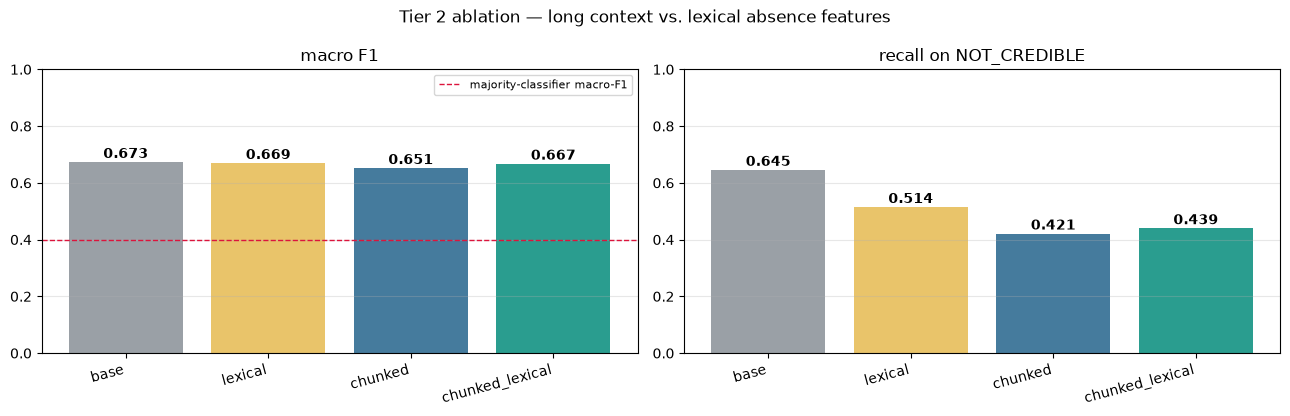

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(len(abl))
for ax, metric, title in [(axes[0], "f1_macro", "macro F1"),
                          (axes[1], "recall_notcred", "recall on NOT_CREDIBLE")]:
    bars = ax.bar(x, abl[metric], color=["#9aa0a6", "#e9c46a", "#457b9d", "#2a9d8f"])
    ax.set_xticks(x); ax.set_xticklabels(abl["variant"], rotation=15, ha="right")
    ax.set_title(title); ax.set_ylim(0, 1); ax.grid(axis="y", alpha=0.3)
    for b, v in zip(bars, abl[metric]):
        ax.text(b.get_x()+b.get_width()/2, v+0.015, f"{v:.3f}", ha="center", fontweight="bold")
axes[0].axhline(0.40, ls="--", c="crimson", lw=1, label="majority-classifier macro-F1")
axes[0].legend(fontsize=8)
plt.suptitle("Tier 2 ablation — long context vs. lexical absence features")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tier2_ablation.png", dpi=150)
plt.show()

### 8.2 Are these differences real? (bootstrap confidence intervals)

In [24]:
def bootstrap_ci(y_true, y_pred, metric, n_boot=4000, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = np.arange(len(y_true))
    vals = []
    for _ in range(n_boot):
        b = rng.choice(idx, len(idx), replace=True)
        if len(np.unique(y_true[b])) < 2:
            continue
        vals.append(metric(y_true[b], y_pred[b]))
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


y_test_arr = test_df["binary_label"].map(LABEL2ID).astype(int).to_numpy()
tok_ref = AutoTokenizer.from_pretrained(PUBMEDBERT)

ci_rows = []
for r in ablation:
    name = r["variant"]
    ds = ArticleDataset(test_df, tok_ref, r["chunked"], r["lexical_features"])
    mdl = ArticleModel(PUBMEDBERT, 2,
                       N_FEATURES if r["lexical_features"] else 0, r["chunked"]).to(DEVICE)
    mdl.load_state_dict(torch.load(MODELS_DIR / f"tier2_{name}" / "model.pt", map_location=DEVICE))
    yp = _predict_ds(mdl, ds).argmax(-1)

    f_lo, f_hi = bootstrap_ci(y_test_arr, yp,
                              lambda a, b: f1_score(a, b, average="macro", zero_division=0))
    r_lo, r_hi = bootstrap_ci(y_test_arr, yp,
                              lambda a, b: precision_recall_fscore_support(
                                  a, b, average="binary", pos_label=LABEL2ID["NOT_CREDIBLE"],
                                  zero_division=0)[1])
    ci_rows.append({"variant": name,
                    "macro_f1": r["f1_macro"], "macro_f1_CI": f"[{f_lo:.3f}, {f_hi:.3f}]",
                    "recall_notcred": r["recall_notcred"], "recall_CI": f"[{r_lo:.3f}, {r_hi:.3f}]"})
    del mdl; torch.cuda.empty_cache()

ci_df = pd.DataFrame(ci_rows)
ci_df.to_csv(OUTPUTS_DIR / "tier2_ablation_ci.csv", index=False)
print(ci_df.to_string(index=False))
print()
print("Reading this: the macro-F1 intervals all overlap heavily, so no variant is")
print("distinguishable from the others on that metric. The recall intervals do NOT all")
print("overlap - the plain model genuinely catches more badly-reported articles.")
print()
print("CONCLUSION: neither long context nor lexical features helps. The added complexity")
print("is not justified, so the simple 512-token model from section 6 is kept as Tier 2.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 38952.14it/s]


[transformers] BertModel LOAD REPORT from: microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract-fulltext
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 42652.49it/s]


[transformers] BertModel LOAD REPORT from: microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract-fulltext
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (3 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 39856.10it/s]


[transformers] BertModel LOAD REPORT from: microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract-fulltext
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


        variant  macro_f1    macro_f1_CI  recall_notcred      recall_CI
           base    0.6727 [0.621, 0.723]          0.6449 [0.555, 0.734]
        lexical    0.6690 [0.613, 0.723]          0.5140 [0.422, 0.609]
        chunked    0.6513 [0.594, 0.707]          0.4206 [0.330, 0.514]
chunked_lexical    0.6668 [0.609, 0.722]          0.4393 [0.346, 0.533]

Reading this: the macro-F1 intervals all overlap heavily, so no variant is
distinguishable from the others on that metric. The recall intervals do NOT all
overlap - the plain model genuinely catches more badly-reported articles.

CONCLUSION: neither long context nor lexical features helps. The added complexity
is not justified, so the simple 512-token model from section 6 is kept as Tier 2.


## 9. Explaining a verdict

In [25]:
import shap
from transformers import TextClassificationPipeline

_pipe = TextClassificationPipeline(
    model=model_bin, tokenizer=tok_bin, device=0 if DEVICE == "cuda" else -1,
    top_k=None, truncation=True, max_length=MAX_LEN)
explainer_t2 = shap.Explainer(_pipe, shap.maskers.Text(r"\W+"))     # whole-word masking

STOPWORDS = set("""
a an the is are was were be been being of to in on at for with and or but not no this that
these those it its as by from has have had do does did will would can could should may might
must if then than so such very just only also more most we our you your they their he she
""".split())

CRITERION_LABEL = {
    "costs": "does not discuss costs",
    "benefits": "does not quantify benefits",
    "harms": "does not quantify harms",
    "evidence_quality": "misjudges the quality of the evidence",
    "disease_mongering": "engages in disease-mongering",
    "independent_srcs": "lacks independent sources / undisclosed conflicts",
    "alternatives": "does not compare with existing alternatives",
    "availability": "does not establish availability",
    "novelty": "overstates novelty",
    "press_release": "relies largely on a press release",
}


def top_words_t2(text, target_label, k=10):
    sv = explainer_t2([text[:3000]])                     # cap length; SHAP is O(n) in words
    toks = [str(t).strip() for t in sv[0].data]
    vals = sv[0].values
    sc = vals[:, LABEL2ID[target_label]] if getattr(vals, "ndim", 1) > 1 else vals
    seen, out = set(), []
    for w, s in sorted(zip(toks, sc), key=lambda x: -x[1]):
        wl = w.lower().strip()
        if not wl or wl in STOPWORDS or len(wl) <= 2 or not re.search(r"[a-z]", wl) or wl in seen:
            continue
        seen.add(wl); out.append((wl, float(s)))
        if len(out) == k:
            break
    return out


def assess_article(text, title="", explain=True, thresholds=None):
    full = (title + ". " + text) if title else text
    enc = tok_bin(full, truncation=True, padding=True, max_length=MAX_LEN, return_tensors="pt")
    enc = {k: v.to(DEVICE) for k, v in enc.items()}
    with torch.no_grad():
        p = torch.softmax(model_bin(**enc).logits, -1).float().cpu().numpy()[0]
    verdict = ID2LABEL[int(p.argmax())]

    enc2 = tok_crit(full, truncation=True, padding=True, max_length=MAX_LEN, return_tensors="pt")
    enc2 = {k: v.to(DEVICE) for k, v in enc2.items()}
    with torch.no_grad():
        cp = torch.sigmoid(model_crit(**enc2).logits).float().cpu().numpy()[0]

    thr = thresholds if thresholds is not None else CRIT_THRESHOLDS
    # score relative to each criterion's own tuned threshold, so the ranking is
    # comparable across criteria with very different output scales
    failures = sorted([(CRITERION_KEYS[j], float(cp[j])) for j in range(len(CRITERION_KEYS))
                       if cp[j] >= thr[CRITERION_KEYS[j]]],
                      key=lambda x: -(x[1] - thr[x[0]]))
    res = {"verdict": verdict, "confidence": float(p.max()),
           "probabilities": {l: float(p[LABEL2ID[l]]) for l in LABELS},
           "failed_criteria": failures,
           "criterion_scores": {k: round(float(cp[j]), 3) for j, k in enumerate(CRITERION_KEYS)}}
    if explain:
        res["top_words"] = top_words_t2(full, verdict)
    return res


def show_assessment(res, title=""):
    print("=" * 78)
    if title:
        print(f"ARTICLE : {title[:100]}")
    print(f"VERDICT : {res['verdict']}  (confidence {res['confidence']:.1%})")
    if res["failed_criteria"]:
        print("FAILS   :")
        for k, s in res["failed_criteria"][:5]:
            print(f"            - {CRITERION_LABEL[k]}  ({s:.0%} confident)")
    else:
        print("FAILS   : none above threshold")
    if res.get("top_words"):
        print(f"KEY WORDS: {', '.join(w for w, _ in res['top_words'][:8])}")
    print()

print("Tier 2 assessment function ready")

Tier 2 assessment function ready


In [26]:
# Demonstrate on two real test articles: one the reviewers rated poorly, one well
_bad  = test_df[test_df.binary_label == "NOT_CREDIBLE"].iloc[0]
_good = test_df[test_df.binary_label == "CREDIBLE"].iloc[0]

for row in (_bad, _good):
    r = assess_article(row["text"], row["title"])
    print(f"[gold label: {row['binary_label']}   reviewer rating: {row['rating']}/5]")
    show_assessment(r, row["title"])

# how well do predicted failures line up with what the reviewer actually flagged?
_gold_fail = [k for k in CRITERION_KEYS if _bad.get(f"fail_{k}") == 1.0]
_pred_fail = [k for k, _ in assess_article(_bad["text"], _bad["title"],
                                           explain=False)["failed_criteria"]]
print("For the NOT_CREDIBLE example above:")
print(f"  reviewer flagged : {', '.join(_gold_fail) or '(none)'}")
print(f"  model predicted  : {', '.join(_pred_fail) or '(none)'}")
_ov = set(_gold_fail) & set(_pred_fail)
print(f"  overlap          : {len(_ov)}/{len(_gold_fail)} of the reviewer's criticisms recovered")

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


[gold label: NOT_CREDIBLE   reviewer rating: 2/5]
ARTICLE : Soy Supplements May Cool Hot Flashes: Study
VERDICT : CREDIBLE  (confidence 55.2%)
FAILS   :
            - does not discuss costs  (47% confident)
KEY WORDS: received, women, took, another, many, looked, risk, researchers



  0%|          | 0/498 [00:00<?, ?it/s]

 73%|███████▎  | 362/498 [00:00<00:00, 3220.93it/s]

[gold label: CREDIBLE   reviewer rating: 5/5]
ARTICLE : Study Finds Low-Salt Diet Ineffective but Draws Criticism From C.D.C.
VERDICT : CREDIBLE  (confidence 60.5%)
FAILS   :
            - does not compare with existing alternatives  (53% confident)
            - misjudges the quality of the evidence  (53% confident)
KEY WORDS: which, people, short-, term, intervention, studies, all, inadequate.

For the NOT_CREDIBLE example above:
  reviewer flagged : costs, benefits, harms, evidence_quality, alternatives
  model predicted  : costs
  overlap          : 1/5 of the reviewer's criticisms recovered


## 10. The router

60 words or fewer goes to Tier 1, longer text to Tier 2.

In [27]:
from sklearn.feature_extraction.text import CountVectorizer

TIER1_DIR = MODELS_DIR / "tier1_final"
ROUTER_WORD_THRESHOLD = 60


class BM25:
    """Okapi BM25. Defined here rather than unpickled from the Tier 1 notebook:
    a pickled instance carries a reference to that notebook's __main__ module and
    cannot be loaded anywhere else. Rebuilding from the saved corpus takes <1s."""
    def __init__(self, docs, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.vec = CountVectorizer(stop_words="english", min_df=2)
        self.tf = self.vec.fit_transform(docs).astype(np.float32)
        dl = np.asarray(self.tf.sum(axis=1)).ravel()
        self.dl, self.avgdl = dl, dl.mean()
        n_dt = np.asarray((self.tf > 0).sum(axis=0)).ravel()
        self.idf = np.log(1 + (self.tf.shape[0] - n_dt + 0.5) / (n_dt + 0.5)).astype(np.float32)

    def scores(self, query):
        q = self.vec.transform([query]); idx = q.indices
        if len(idx) == 0:
            return np.zeros(self.tf.shape[0], dtype=np.float32)
        sub = self.tf[:, idx].toarray()
        denom = sub + self.k1 * (1 - self.b + self.b * (self.dl / self.avgdl))[:, None]
        return ((sub * (self.k1 + 1) / denom) * self.idf[idx]).sum(axis=1)


tier1_available = (TIER1_DIR / "config.json").exists() and \
                  (TIER1_DIR / "retrieval_corpus.parquet").exists()
if tier1_available:
    from transformers import AutoModelForSequenceClassification as _AMSC
    t1_tok = AutoTokenizer.from_pretrained(TIER1_DIR)
    t1_model = _AMSC.from_pretrained(TIER1_DIR).to(DEVICE).eval()

    t1_corpus = pd.read_parquet(TIER1_DIR / "retrieval_corpus.parquet")
    t1_meta = json.load(open(TIER1_DIR / "retriever_meta.json"))
    t1_bm25 = BM25(t1_corpus["text"].tolist())

    _emb_path = TIER1_DIR / "retrieval_corpus_emb.npy"
    t1_emb = np.load(_emb_path) if _emb_path.exists() else None
    t1_dense_id = t1_meta.get("dense_model_id")
    t1_dense_tok = t1_dense_model = None
    if t1_emb is not None and t1_dense_id:
        from transformers import AutoModel as _AM
        t1_dense_tok = AutoTokenizer.from_pretrained(t1_dense_id)
        t1_dense_model = _AM.from_pretrained(t1_dense_id).to(DEVICE).eval()

    T1_LABELS = ["SUPPORTED", "REFUTED", "NEI"]
    print(f"Tier 1 loaded: corpus {len(t1_corpus):,} passages, "
          f"dense encoder = {t1_dense_id or 'none (BM25 only)'}")
else:
    print("Tier 1 artifacts not found - run 1_Tier1_Claim_Verification.ipynb first.")


@torch.no_grad()
def _t1_embed(texts):
    e = t1_dense_tok(texts, padding=True, truncation=True, max_length=256, return_tensors="pt")
    e = {k: v.to(DEVICE) for k, v in e.items()}
    h = t1_dense_model(**e).last_hidden_state
    m = e["attention_mask"].unsqueeze(-1).float()
    return torch.nn.functional.normalize((h * m).sum(1) / m.sum(1), dim=-1).float().cpu().numpy()


def _t1_retrieve(claim, k=3):
    lex = t1_bm25.scores(claim)
    def rr(s):
        o = np.argsort(-s); r = np.zeros(len(s), dtype=np.float32)
        r[o] = 1.0 / (60 + np.arange(1, len(s) + 1)); return r
    fused = rr(lex) + (rr(t1_emb @ _t1_embed([claim])[0]) if t1_dense_model is not None else 0)
    top = np.argsort(-fused)[:k]
    return [t1_corpus["text"].iloc[i] for i in top]


def classify_health_text(text, explain=False):
    n = len(text.split())
    if n <= ROUTER_WORD_THRESHOLD and tier1_available:
        ev = " ".join(_t1_retrieve(text))
        enc = t1_tok(text, ev, truncation="only_second", padding=True,
                     max_length=256, return_tensors="pt")
        enc = {k: v.to(DEVICE) for k, v in enc.items()}
        with torch.no_grad():
            p = torch.softmax(t1_model(**enc).logits, -1).float().cpu().numpy()[0]
        return {"tier": "Tier 1 - claim verification", "word_count": n,
                "verdict": T1_LABELS[int(p.argmax())], "confidence": float(p.max()),
                "evidence_used": ev[:250]}
    res = assess_article(text, explain=explain)
    return {"tier": "Tier 2 - article credibility", "word_count": n,
            "verdict": res["verdict"], "confidence": res["confidence"],
            "failed_criteria": [CRITERION_LABEL[k] for k, _ in res["failed_criteria"][:4]]}


for _t in ["Drinking bleach cures COVID-19.",
           "Vitamin D supplementation reduces the risk of severe COVID-19."]:
    r = classify_health_text(_t)
    print(f"[{r['tier']}, {r['word_count']} words]  {r['verdict']} ({r['confidence']:.1%})")
    print(f"   \"{_t}\"\n")

_art = test_df.iloc[0]
r = classify_health_text(_art["text"])
print(f"[{r['tier']}, {r['word_count']} words]  {r['verdict']} ({r['confidence']:.1%})")
print(f"   {_art['title'][:90]}")
for c in r.get("failed_criteria", []):
    print(f"     - {c}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 13979.39it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 13316.10it/s]

Tier 1 loaded: corpus 6,559 passages, dense encoder = NeuML/pubmedbert-base-embeddings
[Tier 1 - claim verification, 4 words]  REFUTED (99.9%)
   "Drinking bleach cures COVID-19."

[Tier 1 - claim verification, 9 words]  SUPPORTED (99.8%)
   "Vitamin D supplementation reduces the risk of severe COVID-19."

[Tier 2 - article credibility, 792 words]  CREDIBLE (58.9%)
   Study Finds Low-Salt Diet Ineffective but Draws Criticism From C.D.C.
     - does not quantify harms
     - does not compare with existing alternatives
     - engages in disease-mongering
     - misjudges the quality of the evidence


## 11. Saving artifacts

In [28]:
metrics_t2 = {
    "task": "article credibility assessment (CREDIBLE / NOT_CREDIBLE) + 10-criterion multi-label",
    "dataset": "FakeHealth (HealthRelease + HealthStory)",
    "n_articles": int(len(art)),
    "split_sizes": {"train": int(len(train_df)), "validation": int(len(val_df)),
                    "test": int(len(test_df))},
    "majority_baseline": float(majority),
    "selected_model": "PubMedBERT, 512 tokens (section 6)",
    "binary_results": {r["run"]: {k: v for k, v in r.items() if k != "backbone"}
                       for r in bin_results},
    "criteria_macro_f1": float(crit_df["f1"].mean()),
    "criteria_per_class": crit_df.set_index("criterion")["f1"].round(3).to_dict(),
    "composed_vs_direct": comp_tbl.to_dict(orient="records"),
    "ablation": ablation,
    "ablation_conclusion": ("neither chunked long-context nor lexical absence features "
                            "improved macro-F1 beyond bootstrap noise; both reduced recall "
                            "on NOT_CREDIBLE. The simple 512-token model is retained."),
    "router_word_threshold": ROUTER_WORD_THRESHOLD,
    "criteria_thresholds": CRIT_THRESHOLDS,
}
with open(OUTPUTS_DIR / "tier2_metrics.json", "w") as f:
    json.dump(metrics_t2, f, indent=2, default=float)

T2_FINAL = MODELS_DIR / "tier2_final"
T2_FINAL.mkdir(parents=True, exist_ok=True)
model_bin.save_pretrained(T2_FINAL); tok_bin.save_pretrained(T2_FINAL)
(T2_FINAL / "criteria").mkdir(exist_ok=True)
model_crit.save_pretrained(T2_FINAL / "criteria"); tok_crit.save_pretrained(T2_FINAL / "criteria")
with open(T2_FINAL / "criteria_keys.json", "w") as f:
    json.dump({"keys": CRITERION_KEYS, "labels": CRITERION_LABEL,
               "thresholds": CRIT_THRESHOLDS}, f, indent=2)

print(f"binary model   -> {T2_FINAL}")
print(f"criteria model -> {T2_FINAL/'criteria'}")
print(f"metrics        -> {OUTPUTS_DIR/'tier2_metrics.json'}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.46it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.44it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.59it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.58it/s]

binary model   -> C:\Users\nihal\Desktop\Project Phase\models\tier2_final
criteria model -> C:\Users\nihal\Desktop\Project Phase\models\tier2_final\criteria
metrics        -> C:\Users\nihal\Desktop\Project Phase\outputs\tier2_metrics.json
